In [ ]:
# Basic libraries
import numpy as np                      # arrays of numbers (our images)
import matplotlib.pyplot as plt         # graphs and showing images
import urllib.request, os               # downloading the .npy files

# PyTorch (deep learning)
import torch                             # The core PyTorch library for tensor operations
import torch.nn as nn                    # Contains building blocks like layers (Linear, Conv2d) and loss functions
import torch.nn.functional as F          # Provides functional operations like activations (ReLU) and pooling
import torchvision                       # gives us ResNet-50 and image transforms

# TensorDataset: Wraps features and labels into a single dataset object
# DataLoader: Handles mini-batching, shuffling, and parallel data loading
from torch.utils.data import TensorDataset, DataLoader

# For splitting data into train / validation / test
from sklearn.model_selection import train_test_split

# Use the GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

# Results of every experiment will be stored here
results = {}

Using: cuda


In [ ]:
categories = [
    # 1-10
    "apple", "banana", "cat", "dog", "car", "house", "tree", "star", "sun", "fish",
    # 11-20
    "bicycle", "airplane", "clock", "cloud", "cup", "eye", "flower", "guitar", "hammer", "hat",
    # 21-30
    "key", "ladder", "leaf", "mushroom", "pizza", "rainbow", "scissors", "shoe", "snake", "umbrella",
    # 31-50
    "book", "bird", "butterfly", "camera", "candle", "chair", "crown", "donut", "door", "envelope",
    "eyeglasses", "fork", "giraffe", "helicopter", "ice cream", "light bulb", "lollipop", "mountain", "octopus", "pencil",
    # 51-100
    "rabbit", "sailboat", "shark", "snowman", "spoon", "strawberry", "table", "television", "toothbrush", "truck",
    "watermelon", "windmill", "zebra", "ant", "axe", "basketball", "bee", "bridge", "cactus", "carrot",
    "circle", "cookie", "crab", "elephant", "feather", "frog", "grapes", "hourglass", "lion", "monkey",
    "owl", "pear", "penguin", "piano", "pig", "pineapple", "skull", "snail", "sock", "spider",
    "square", "suitcase", "swan", "teapot", "tent", "tornado", "trumpet", "violin", "whale", "wine glass",
]
print("Number of categories:", len(categories))

Number of categories: 100


In [ ]:
data = {}   # data["apple"] = 1000 drawings of apples, each 28x28

for name in categories:
    url = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/" + name.replace(" ", "%20") + ".npy"
    urllib.request.urlretrieve(url, "temp.npy")                    # download the file

    drawings = np.load("temp.npy", mmap_mode="r")                  # shape: (number of drawings, 784)
    pick = np.random.RandomState(42).choice(len(drawings), 1000, replace=False)   # 1000 random ones
    data[name] = drawings[np.sort(pick)].reshape(-1, 28, 28)       # 784 numbers -> 28 x 28 image

    print(f"{name:12s} total drawings: {len(drawings):,}  -> kept 1000")
    del drawings
    os.remove("temp.npy")                                          # delete the big file

apple        total drawings: 144,722  -> kept 1000
banana       total drawings: 307,936  -> kept 1000
cat          total drawings: 123,202  -> kept 1000
dog          total drawings: 152,159  -> kept 1000
car          total drawings: 182,764  -> kept 1000
house        total drawings: 135,420  -> kept 1000
tree         total drawings: 144,721  -> kept 1000
star         total drawings: 137,619  -> kept 1000
sun          total drawings: 133,781  -> kept 1000
fish         total drawings: 134,150  -> kept 1000
bicycle      total drawings: 126,527  -> kept 1000
airplane     total drawings: 151,623  -> kept 1000
clock        total drawings: 120,536  -> kept 1000
cloud        total drawings: 120,265  -> kept 1000
cup          total drawings: 130,721  -> kept 1000
eye          total drawings: 125,888  -> kept 1000
flower       total drawings: 144,818  -> kept 1000
guitar       total drawings: 120,451  -> kept 1000
hammer       total drawings: 119,012  -> kept 1000
hat          total drawings: 22

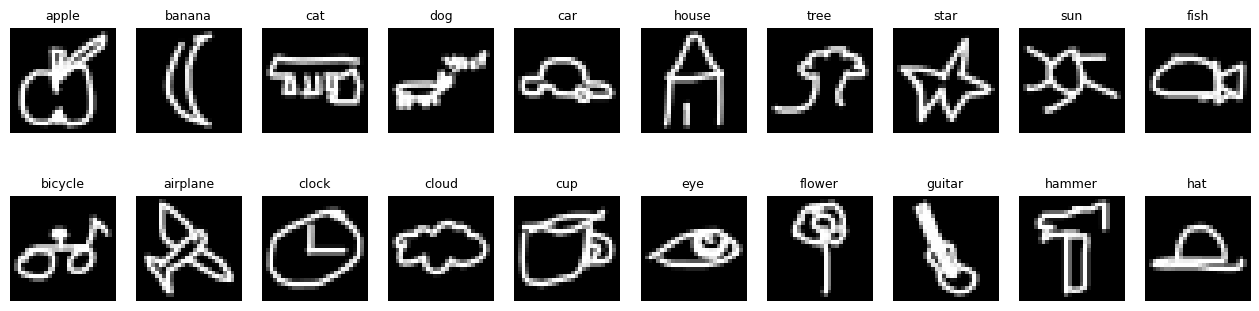

In [ ]:
# One drawing from each of the first 20 categories
plt.figure(figsize=(16, 4))
for i in range(20):
    plt.subplot(2, 10, i + 1)
    plt.imshow(data[categories[i]][0], cmap="gray")   # white strokes on black background
    plt.title(categories[i], fontsize=9)
    plt.axis("off")
plt.show()

In [ ]:
N = 10              # number of categories (the first 10 in our list)
EPOCHS = 15         # paper: 15 epochs for 10 categories
BATCH_SIZE = 64     # paper: batch size 64
LR = 1e-5           # paper: learning rate 0.00001

In [ ]:
# Stack all drawings into one array, and make a label for each drawing
# label 0 = apple, 1 = banana, 2 = cat, ... 9 = fish
X = np.concatenate([data[c] for c in categories[:N]])        # shape: (10000, 28, 28)
y = np.concatenate([np.full(1000, i) for i in range(N)])     # shape: (10000,)

# Split: 80% train, 10% validation, 10% test (same as the paper)
X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=42)

# Convert to PyTorch tensors
# pixels 0..255 -> 0..1, and add a channel dimension: (28, 28) -> (1, 28, 28)
X_train = torch.tensor(X_train).float().div(255).unsqueeze(1)
X_val = torch.tensor(X_val).float().div(255).unsqueeze(1)
X_test = torch.tensor(X_test).float().div(255).unsqueeze(1)
y_train, y_val, y_test = torch.tensor(y_train), torch.tensor(y_val), torch.tensor(y_test)

# DataLoaders feed the model 64 images at a time
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=BATCH_SIZE)

print("Train:", len(X_train), "| Validation:", len(X_val), "| Test:", len(X_test))

Train: 8000 | Validation: 1000 | Test: 1000


In [ ]:
# ImageNet mean and std (the pretrained weights expect images normalized like this)
mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

# Augmentation for training images only (same as the paper)
augment = torchvision.transforms.Compose([
    torchvision.transforms.RandomHorizontalFlip(),   # flip left-right half the time
    torchvision.transforms.RandomRotation(10),       # rotate between -10 and +10 degrees
])

In [ ]:
model = torchvision.models.resnet50(weights="IMAGENET1K_V1")   # standard ResNet-50, ImageNet weights
model.fc = nn.Linear(2048, N)                                   # new last layer: 2048 features -> 10 categories
model = model.to(device)

loss_fn = nn.CrossEntropyLoss()                                 # paper: cross-entropy loss
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)        # paper: AdamW optimizer

In [ ]:
train_losses, train_accs, val_losses, val_accs = [], [], [], []

for epoch in range(EPOCHS):

    # ----- TRAINING: the model learns -----
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        images = torch.stack([augment(img) for img in images])                    # random flip / rotate
        images = F.interpolate(images, size=(224, 224), mode="bilinear")          # resize 28x28 -> 224x224
        images = images.repeat(1, 3, 1, 1)                                        # 1 gray channel -> 3 channels
        images = (images - mean) / std                                            # normalize

        outputs = model(images)                  # forward pass: one score per category
        loss = loss_fn(outputs, labels)          # how wrong the scores are

        optimizer.zero_grad()                    # clear old gradients
        loss.backward()                          # backward pass: compute gradients
        optimizer.step()                         # update the weights

        total_loss += loss.item() * len(labels)
        correct += (outputs.argmax(1) == labels).sum().item()   # highest score = predicted category
        total += len(labels)

    train_losses.append(total_loss / total)
    train_accs.append(100 * correct / total)

    # ----- VALIDATION: check on images the model is not trained on -----
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():                        # no learning here
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            images = F.interpolate(images, size=(224, 224), mode="bilinear")
            images = images.repeat(1, 3, 1, 1)
            images = (images - mean) / std

            outputs = model(images)
            total_loss += loss_fn(outputs, labels).item() * len(labels)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += len(labels)

    val_losses.append(total_loss / total)
    val_accs.append(100 * correct / total)

    print(f"Epoch {epoch+1}/{EPOCHS} | Train loss {train_losses[-1]:.4f}, acc {train_accs[-1]:.2f}% "
          f"| Val loss {val_losses[-1]:.4f}, acc {val_accs[-1]:.2f}%")

Epoch 1/15 | Train loss 0.6554, acc 86.21% | Val loss 0.3706, acc 91.00%
Epoch 2/15 | Train loss 0.3342, acc 91.40% | Val loss 0.2468, acc 92.50%
Epoch 3/15 | Train loss 0.2484, acc 93.04% | Val loss 0.2360, acc 92.80%
Epoch 4/15 | Train loss 0.1972, acc 94.41% | Val loss 0.1961, acc 94.30%
Epoch 5/15 | Train loss 0.1768, acc 94.56% | Val loss 0.1949, acc 94.10%
Epoch 6/15 | Train loss 0.1507, acc 95.53% | Val loss 0.1861, acc 93.90%
Epoch 7/15 | Train loss 0.1395, acc 95.65% | Val loss 0.1820, acc 94.60%
Epoch 8/15 | Train loss 0.1169, acc 96.41% | Val loss 0.1869, acc 94.20%
Epoch 9/15 | Train loss 0.1088, acc 96.62% | Val loss 0.1948, acc 94.00%
Epoch 10/15 | Train loss 0.0922, acc 97.40% | Val loss 0.1940, acc 93.70%
Epoch 11/15 | Train loss 0.0820, acc 97.55% | Val loss 0.1885, acc 94.30%
Epoch 12/15 | Train loss 0.0765, acc 97.71% | Val loss 0.1894, acc 94.10%
Epoch 13/15 | Train loss 0.0656, acc 98.09% | Val loss 0.2010, acc 94.00%
Epoch 14/15 | Train loss 0.0556, acc 98.45% | V

In [ ]:
model.eval()
total_loss, correct, total = 0, 0, 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        images = F.interpolate(images, size=(224, 224), mode="bilinear")
        images = images.repeat(1, 3, 1, 1)
        images = (images - mean) / std

        outputs = model(images)
        total_loss += loss_fn(outputs, labels).item() * len(labels)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += len(labels)

print(f"TEST ({N} categories): accuracy {100 * correct / total:.2f}%, loss {total_loss / total:.4f}")
print(f"PAPER (ResNet-50, 10 categories): accuracy 94.60%, loss 0.1815")

TEST (10 categories): accuracy 95.70%, loss 0.1542
PAPER (ResNet-50, 10 categories): accuracy 94.60%, loss 0.1815


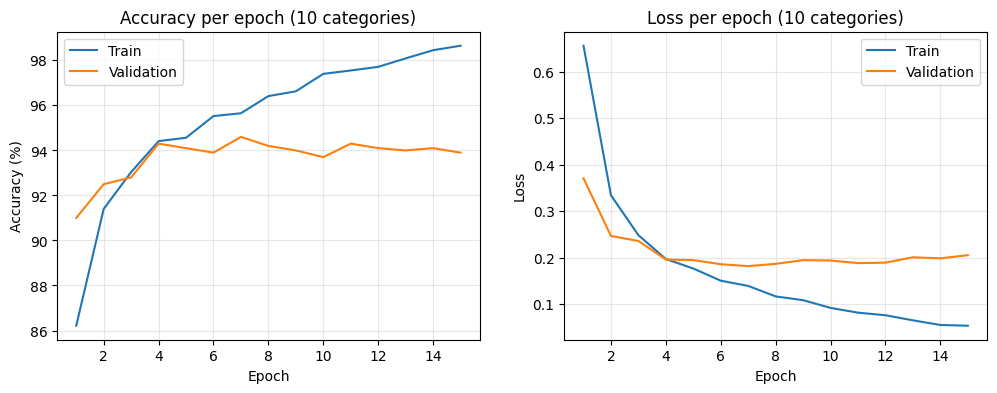

In [ ]:
epochs = range(1, EPOCHS + 1)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_accs, label="Train")
plt.plot(epochs, val_accs, label="Validation")
plt.title("Accuracy per epoch (10 categories)")
plt.xlabel("Epoch"); plt.ylabel("Accuracy (%)"); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs, train_losses, label="Train")
plt.plot(epochs, val_losses, label="Validation")
plt.title("Loss per epoch (10 categories)")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(alpha=0.3)

plt.show()

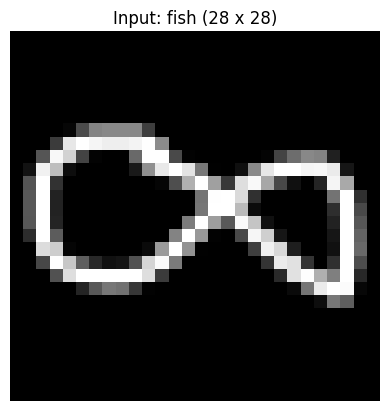

After conv1: (1, 64, 112, 112)


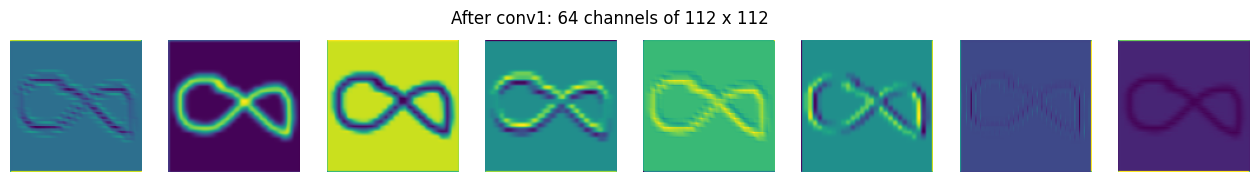

After bn1: (1, 64, 112, 112)


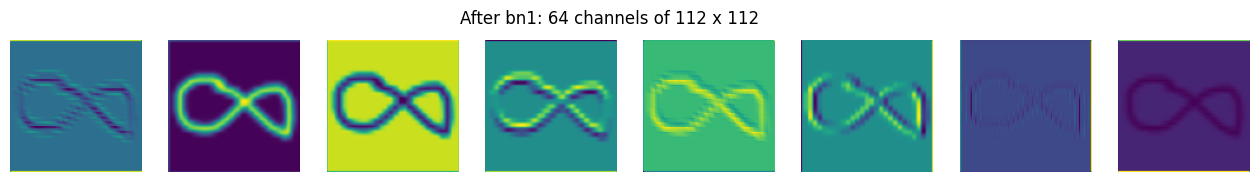

After relu: (1, 64, 112, 112)


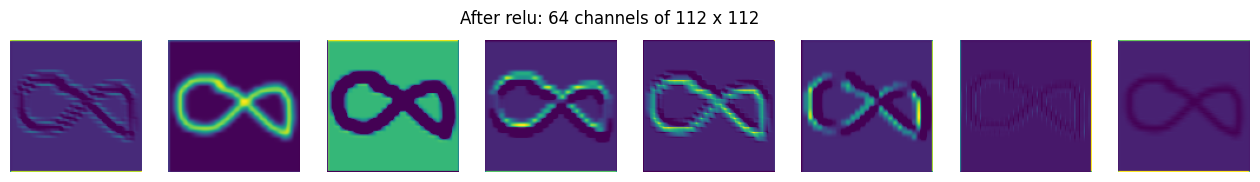

After maxpool: (1, 64, 56, 56)


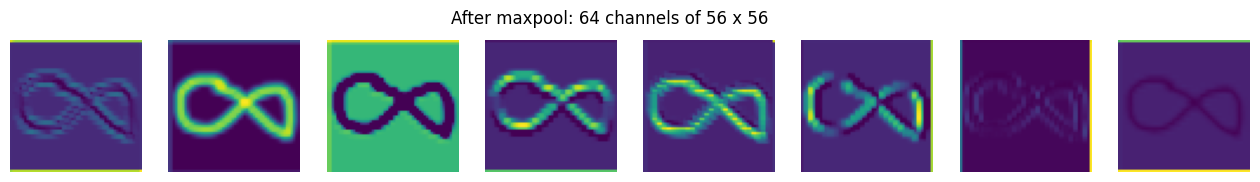

After layer1: (1, 256, 56, 56)


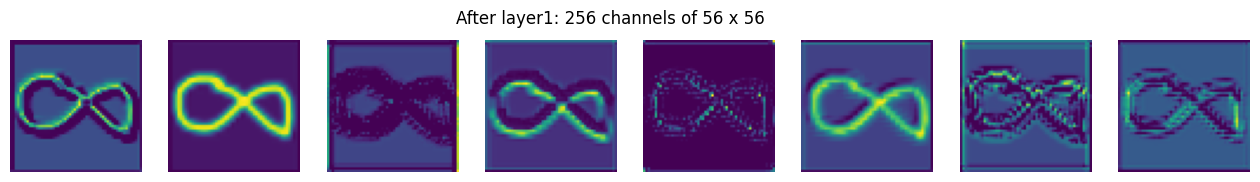

After layer2: (1, 512, 28, 28)


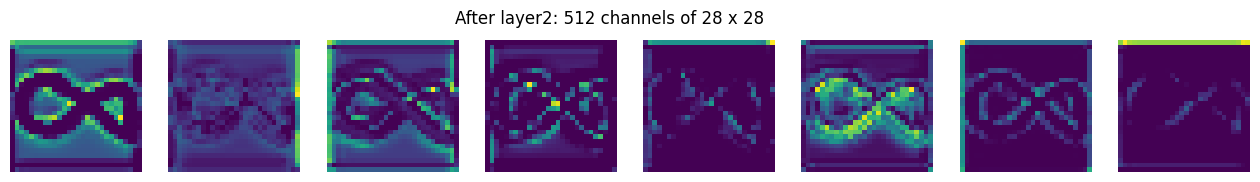

After layer3: (1, 1024, 14, 14)


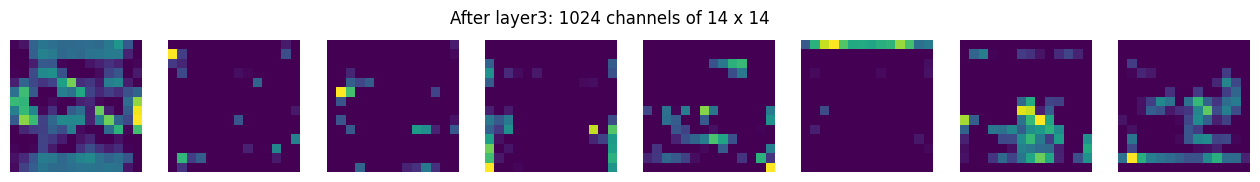

After layer4: (1, 2048, 7, 7)


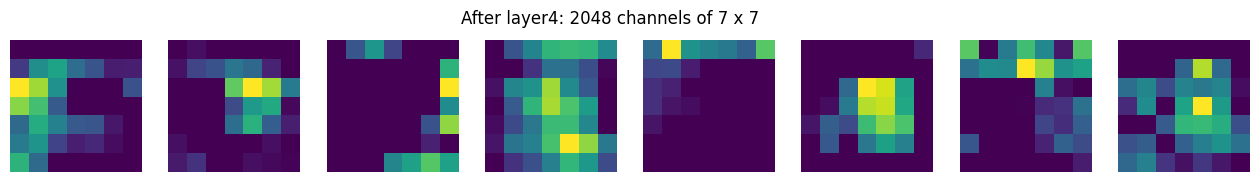

After avgpool: (1, 2048)
After fc: (1, 10)
Prediction: fish


In [ ]:
# Find the first fish in the test set
fish_index = (y_test == categories.index("fish")).nonzero()[0].item()
image = X_test[fish_index:fish_index + 1].to(device)                     # shape: (1, 1, 28, 28)

plt.imshow(image[0, 0].cpu(), cmap="gray"); plt.title("Input: fish (28 x 28)"); plt.axis("off"); plt.show()

# Prepare it exactly like the training images
x = F.interpolate(image, size=(224, 224), mode="bilinear")
x = x.repeat(1, 3, 1, 1)
x = (x - mean) / std

# The layers of ResNet-50, in order
layers = [("conv1", model.conv1), ("bn1", model.bn1), ("relu", model.relu), ("maxpool", model.maxpool),
          ("layer1", model.layer1), ("layer2", model.layer2), ("layer3", model.layer3), ("layer4", model.layer4)]

model.eval()
with torch.no_grad():
    for name, layer in layers:
        x = layer(x)                                         # pass through ONE layer
        print(f"After {name}: {tuple(x.shape)}")              # (batch, channels, height, width)

        plt.figure(figsize=(16, 2))
        for i in range(8):                                   # show the first 8 channels
            plt.subplot(1, 8, i + 1)
            plt.imshow(x[0, i].cpu(), cmap="viridis")
            plt.axis("off")
        plt.suptitle(f"After {name}: {x.shape[1]} channels of {x.shape[2]} x {x.shape[3]}")
        plt.show()

    x = model.avgpool(x)                  # each 7x7 map -> 1 number  (2048 numbers)
    x = torch.flatten(x, 1)
    print("After avgpool:", tuple(x.shape))
    x = model.fc(x)                       # 2048 numbers -> 10 category scores
    print("After fc:", tuple(x.shape))
    print("Prediction:", categories[x.argmax(1).item()])

Train: 16000 | Validation: 2000 | Test: 2000
Epoch 1/15 | Train loss 1.7465, acc 63.49% | Val loss 0.7822, acc 83.05%
Epoch 2/15 | Train loss 0.5807, acc 87.38% | Val loss 0.4014, acc 89.95%
Epoch 3/15 | Train loss 0.3681, acc 91.11% | Val loss 0.3087, acc 92.40%
Epoch 4/15 | Train loss 0.2822, acc 92.89% | Val loss 0.2737, acc 92.80%
Epoch 5/15 | Train loss 0.2399, acc 93.78% | Val loss 0.2558, acc 93.40%
Epoch 6/15 | Train loss 0.2088, acc 94.39% | Val loss 0.2541, acc 92.90%
Epoch 7/15 | Train loss 0.1796, acc 95.33% | Val loss 0.2401, acc 93.85%
Epoch 8/15 | Train loss 0.1646, acc 95.54% | Val loss 0.2359, acc 93.50%
Epoch 9/15 | Train loss 0.1446, acc 96.06% | Val loss 0.2311, acc 93.75%
Epoch 10/15 | Train loss 0.1276, acc 96.53% | Val loss 0.2274, acc 93.65%
Epoch 11/15 | Train loss 0.1190, acc 96.81% | Val loss 0.2319, acc 94.05%
Epoch 12/15 | Train loss 0.1054, acc 97.12% | Val loss 0.2395, acc 93.50%
Epoch 13/15 | Train loss 0.0933, acc 97.44% | Val loss 0.2391, acc 93.60%
Ep

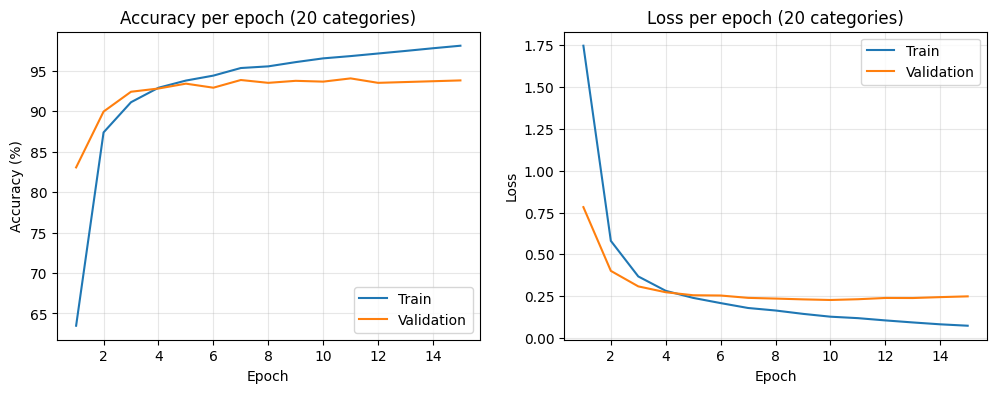

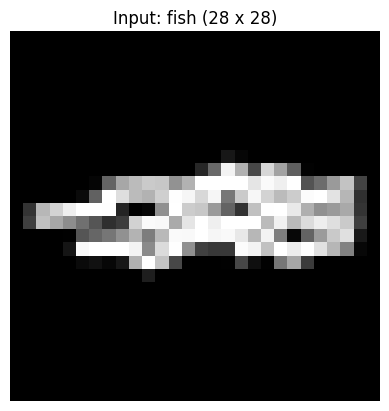

After conv1: (1, 64, 112, 112)


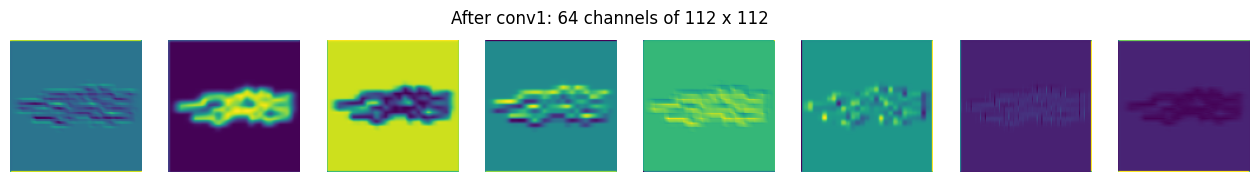

After bn1: (1, 64, 112, 112)


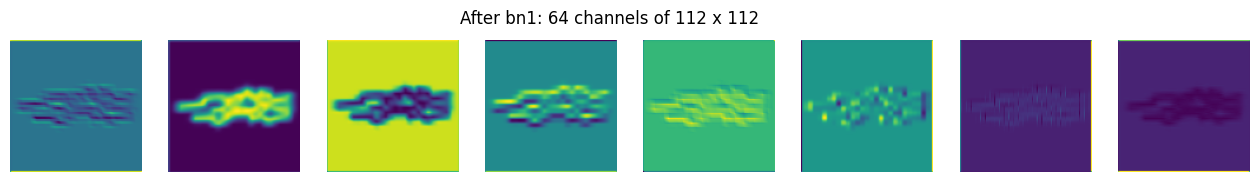

After relu: (1, 64, 112, 112)


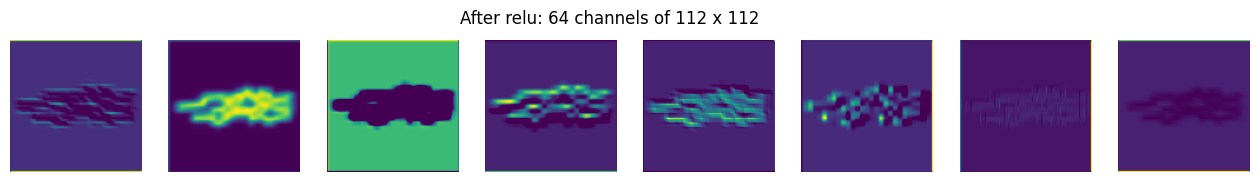

After maxpool: (1, 64, 56, 56)


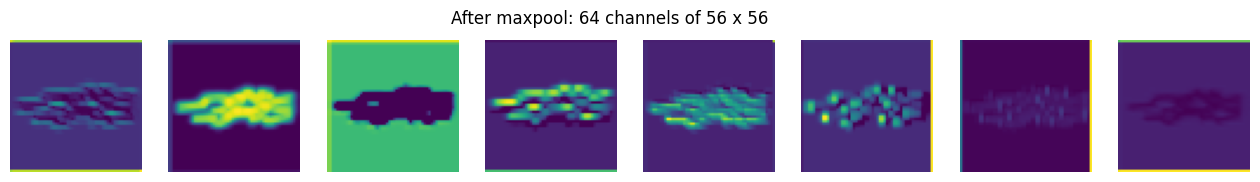

After layer1: (1, 256, 56, 56)


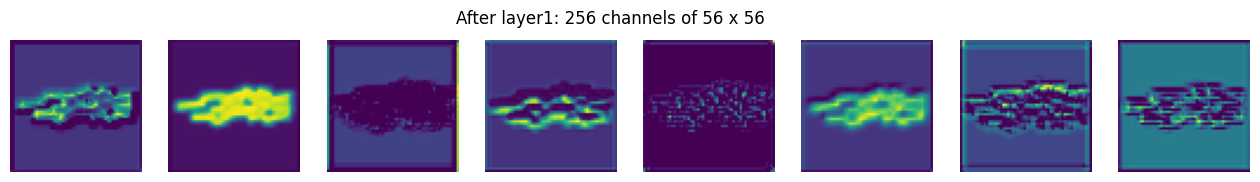

After layer2: (1, 512, 28, 28)


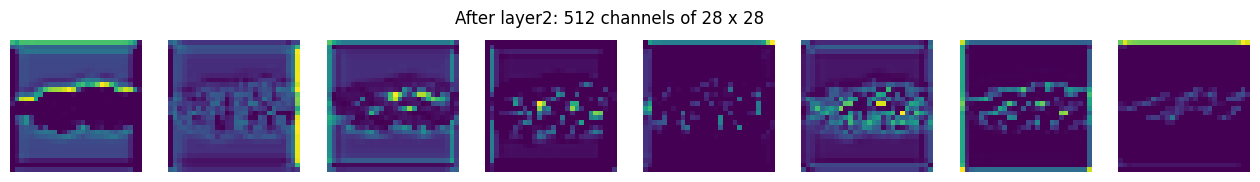

After layer3: (1, 1024, 14, 14)


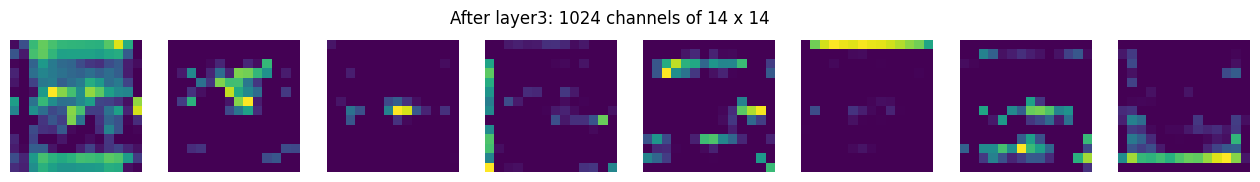

After layer4: (1, 2048, 7, 7)


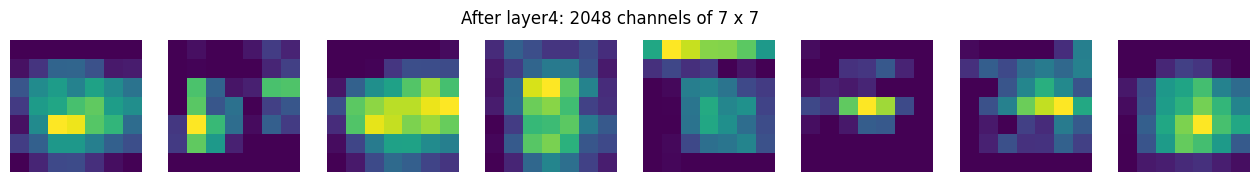

After avgpool: (1, 2048)
After fc: (1, 20)
Prediction: airplane


In [ ]:
# =====================================================================
# SETTINGS (same as the paper)
# =====================================================================
N = 20              # number of categories (the first 20 in our list)
EPOCHS = 15         # paper: 15 epochs for 20 categories
BATCH_SIZE = 64     # paper: batch size 64
LR = 1e-5           # paper: learning rate 0.00001

# =====================================================================
# BUILD THE DATASET AND SPLIT IT
# =====================================================================
X = np.concatenate([data[c] for c in categories[:N]])        # all drawings of the first N categories
y = np.concatenate([np.full(1000, i) for i in range(N)])     # label for each drawing

# Split: 80% train, 10% validation, 10% test
X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=42)

# Convert to PyTorch tensors: pixels 0..255 -> 0..1, add channel: (28, 28) -> (1, 28, 28)
X_train = torch.tensor(X_train).float().div(255).unsqueeze(1)
X_val = torch.tensor(X_val).float().div(255).unsqueeze(1)
X_test = torch.tensor(X_test).float().div(255).unsqueeze(1)
y_train, y_val, y_test = torch.tensor(y_train), torch.tensor(y_val), torch.tensor(y_test)

# DataLoaders feed the model 64 images at a time
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=BATCH_SIZE)
print("Train:", len(X_train), "| Validation:", len(X_val), "| Test:", len(X_test))

# ImageNet mean and std (for normalizing)
mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

# Augmentation for training images only (same as the paper)
augment = torchvision.transforms.Compose([
    torchvision.transforms.RandomHorizontalFlip(),   # flip left-right half the time
    torchvision.transforms.RandomRotation(10),       # rotate between -10 and +10 degrees
])

# =====================================================================
# CREATE A FRESH RESNET-50 MODEL
# =====================================================================
model = torchvision.models.resnet50(weights="IMAGENET1K_V1")   # standard ResNet-50, ImageNet weights
model.fc = nn.Linear(2048, N)                                   # new last layer: 2048 features -> N categories
model = model.to(device)

loss_fn = nn.CrossEntropyLoss()                                 # paper: cross-entropy loss
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)        # paper: AdamW optimizer

# =====================================================================
# TRAIN AND VALIDATE
# =====================================================================
train_losses, train_accs, val_losses, val_accs = [], [], [], []

for epoch in range(EPOCHS):

    # ----- TRAINING -----
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        images = torch.stack([augment(img) for img in images])                    # random flip / rotate
        images = F.interpolate(images, size=(224, 224), mode="bilinear")          # resize 28x28 -> 224x224
        images = images.repeat(1, 3, 1, 1)                                        # 1 channel -> 3 channels
        images = (images - mean) / std                                            # normalize

        outputs = model(images)                  # forward pass
        loss = loss_fn(outputs, labels)          # how wrong the scores are

        optimizer.zero_grad()                    # clear old gradients
        loss.backward()                          # backward pass
        optimizer.step()                         # update the weights

        total_loss += loss.item() * len(labels)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += len(labels)

    train_losses.append(total_loss / total)
    train_accs.append(100 * correct / total)

    # ----- VALIDATION -----
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            images = F.interpolate(images, size=(224, 224), mode="bilinear")
            images = images.repeat(1, 3, 1, 1)
            images = (images - mean) / std

            outputs = model(images)
            total_loss += loss_fn(outputs, labels).item() * len(labels)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += len(labels)

    val_losses.append(total_loss / total)
    val_accs.append(100 * correct / total)

    print(f"Epoch {epoch+1}/{EPOCHS} | Train loss {train_losses[-1]:.4f}, acc {train_accs[-1]:.2f}% "
          f"| Val loss {val_losses[-1]:.4f}, acc {val_accs[-1]:.2f}%")

# =====================================================================
# TEST
# =====================================================================
model.eval()
total_loss, correct, total = 0, 0, 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        images = F.interpolate(images, size=(224, 224), mode="bilinear")
        images = images.repeat(1, 3, 1, 1)
        images = (images - mean) / std

        outputs = model(images)
        total_loss += loss_fn(outputs, labels).item() * len(labels)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += len(labels)

print(f"\nTEST ({N} categories): accuracy {100 * correct / total:.2f}%, loss {total_loss / total:.4f}")
print(f"PAPER (ResNet-50, {N} categories): accuracy 93.70%, loss 0.2235")

# =====================================================================
# ACCURACY AND LOSS GRAPHS
# =====================================================================
epochs = range(1, EPOCHS + 1)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_accs, label="Train")
plt.plot(epochs, val_accs, label="Validation")
plt.title(f"Accuracy per epoch ({N} categories)")
plt.xlabel("Epoch"); plt.ylabel("Accuracy (%)"); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs, train_losses, label="Train")
plt.plot(epochs, val_losses, label="Validation")
plt.title(f"Loss per epoch ({N} categories)")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

# =====================================================================
# LAYER BY LAYER OUTPUT FOR ONE FISH DRAWING
# =====================================================================
fish_index = (y_test == categories.index("fish")).nonzero()[0].item()   # first fish in the test set
image = X_test[fish_index:fish_index + 1].to(device)                     # shape: (1, 1, 28, 28)

plt.imshow(image[0, 0].cpu(), cmap="gray"); plt.title("Input: fish (28 x 28)"); plt.axis("off"); plt.show()

x = F.interpolate(image, size=(224, 224), mode="bilinear")
x = x.repeat(1, 3, 1, 1)
x = (x - mean) / std

layers = [("conv1", model.conv1), ("bn1", model.bn1), ("relu", model.relu), ("maxpool", model.maxpool),
          ("layer1", model.layer1), ("layer2", model.layer2), ("layer3", model.layer3), ("layer4", model.layer4)]

model.eval()
with torch.no_grad():
    for name, layer in layers:
        x = layer(x)                                         # pass through ONE layer
        print(f"After {name}: {tuple(x.shape)}")

        plt.figure(figsize=(16, 2))
        for i in range(8):                                   # show the first 8 channels
            plt.subplot(1, 8, i + 1)
            plt.imshow(x[0, i].cpu(), cmap="viridis")
            plt.axis("off")
        plt.suptitle(f"After {name}: {x.shape[1]} channels of {x.shape[2]} x {x.shape[3]}")
        plt.show()

    x = model.avgpool(x)                  # each 7x7 map -> 1 number  (2048 numbers)
    x = torch.flatten(x, 1)
    print("After avgpool:", tuple(x.shape))
    x = model.fc(x)                       # 2048 numbers -> N category scores
    print("After fc:", tuple(x.shape))
    print("Prediction:", categories[x.argmax(1).item()])

Train: 24000 | Validation: 3000 | Test: 3000
Epoch 1/15 | Train loss 2.0051, acc 60.67% | Val loss 0.9371, acc 82.60%
Epoch 2/15 | Train loss 0.6942, acc 85.22% | Val loss 0.4624, acc 89.57%
Epoch 3/15 | Train loss 0.4456, acc 89.48% | Val loss 0.3748, acc 90.83%
Epoch 4/15 | Train loss 0.3571, acc 91.02% | Val loss 0.3217, acc 91.77%
Epoch 5/15 | Train loss 0.2970, acc 92.45% | Val loss 0.2998, acc 92.07%
Epoch 6/15 | Train loss 0.2659, acc 93.09% | Val loss 0.2930, acc 92.43%
Epoch 7/15 | Train loss 0.2349, acc 93.89% | Val loss 0.2800, acc 92.53%
Epoch 8/15 | Train loss 0.2072, acc 94.62% | Val loss 0.2829, acc 92.53%
Epoch 9/15 | Train loss 0.1850, acc 95.22% | Val loss 0.2755, acc 92.77%
Epoch 10/15 | Train loss 0.1731, acc 95.37% | Val loss 0.2784, acc 92.60%
Epoch 11/15 | Train loss 0.1528, acc 96.01% | Val loss 0.2604, acc 92.97%
Epoch 12/15 | Train loss 0.1373, acc 96.30% | Val loss 0.2752, acc 92.70%
Epoch 13/15 | Train loss 0.1241, acc 96.79% | Val loss 0.2691, acc 92.97%
Ep

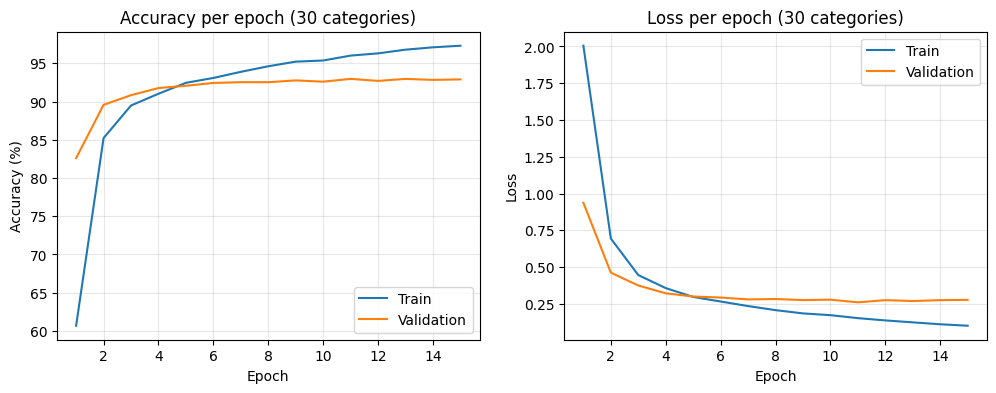

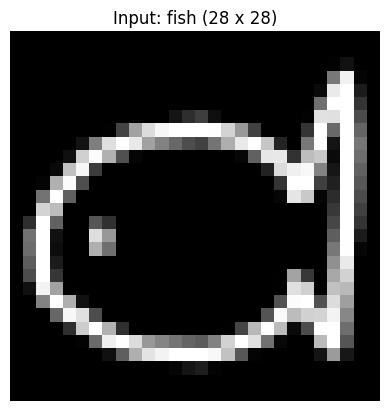

After conv1: (1, 64, 112, 112)


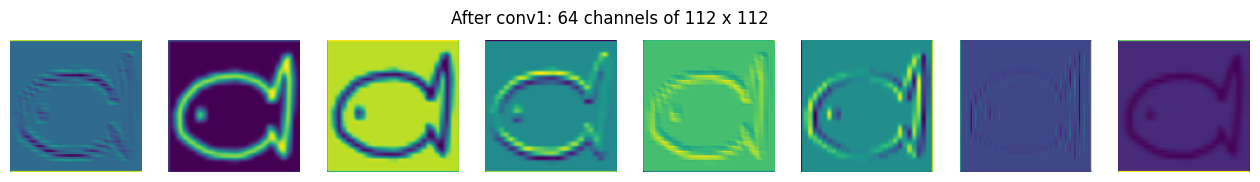

After bn1: (1, 64, 112, 112)


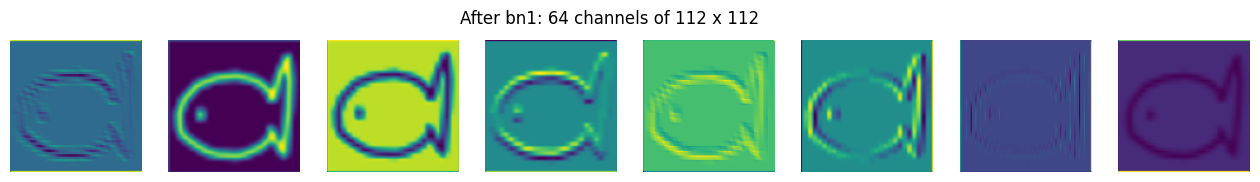

After relu: (1, 64, 112, 112)


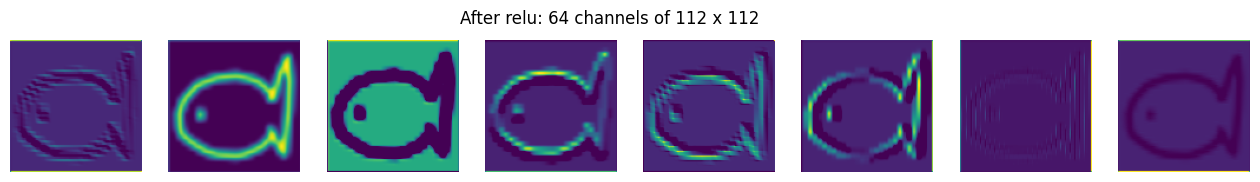

After maxpool: (1, 64, 56, 56)


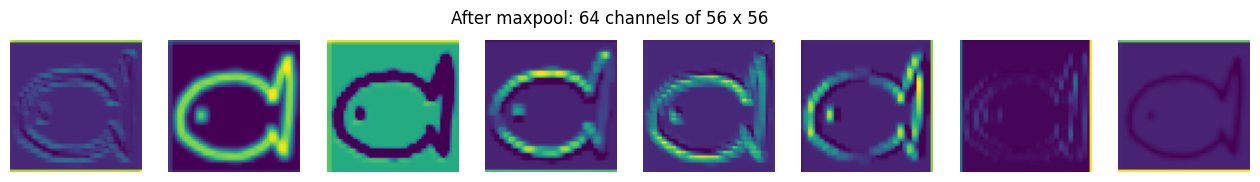

After layer1: (1, 256, 56, 56)


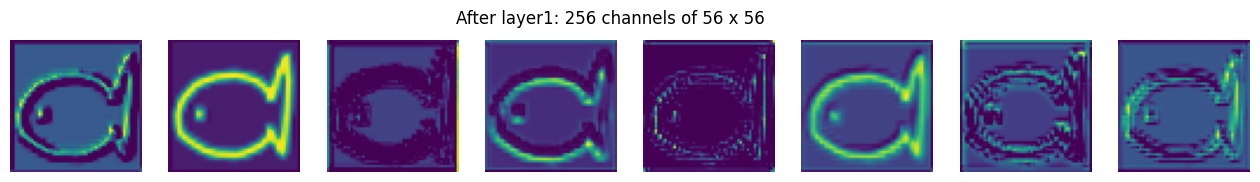

After layer2: (1, 512, 28, 28)


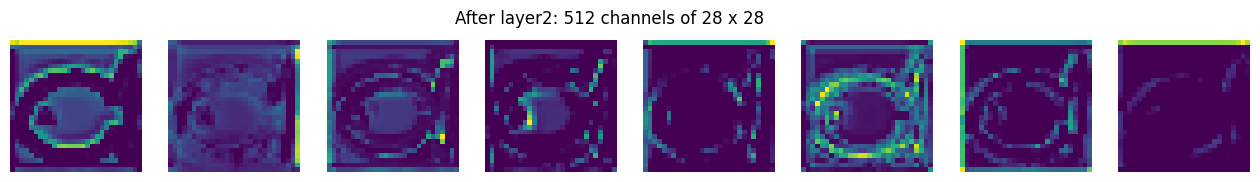

After layer3: (1, 1024, 14, 14)


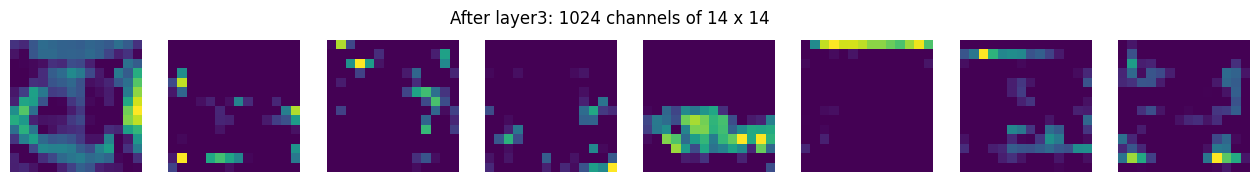

After layer4: (1, 2048, 7, 7)


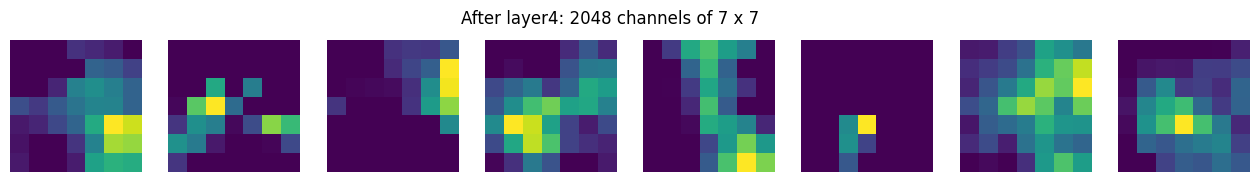

After avgpool: (1, 2048)
After fc: (1, 30)
Prediction: fish


In [ ]:
# =====================================================================
# SETTINGS (same as the paper)
# =====================================================================
N = 30              # number of categories (the first 30 in our list)
EPOCHS = 15         # paper: 15 epochs for 30 categories
BATCH_SIZE = 64     # paper: batch size 64
LR = 1e-5           # paper: learning rate 0.00001

# =====================================================================
# BUILD THE DATASET AND SPLIT IT
# =====================================================================
X = np.concatenate([data[c] for c in categories[:N]])        # all drawings of the first N categories
y = np.concatenate([np.full(1000, i) for i in range(N)])     # label for each drawing

# Split: 80% train, 10% validation, 10% test
X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=42)

# Convert to PyTorch tensors: pixels 0..255 -> 0..1, add channel: (28, 28) -> (1, 28, 28)
X_train = torch.tensor(X_train).float().div(255).unsqueeze(1)
X_val = torch.tensor(X_val).float().div(255).unsqueeze(1)
X_test = torch.tensor(X_test).float().div(255).unsqueeze(1)
y_train, y_val, y_test = torch.tensor(y_train), torch.tensor(y_val), torch.tensor(y_test)

# DataLoaders feed the model 64 images at a time
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=BATCH_SIZE)
print("Train:", len(X_train), "| Validation:", len(X_val), "| Test:", len(X_test))

# ImageNet mean and std (for normalizing)
mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

# Augmentation for training images only (same as the paper)
augment = torchvision.transforms.Compose([
    torchvision.transforms.RandomHorizontalFlip(),   # flip left-right half the time
    torchvision.transforms.RandomRotation(10),       # rotate between -10 and +10 degrees
])

# =====================================================================
# CREATE A FRESH RESNET-50 MODEL
# =====================================================================
model = torchvision.models.resnet50(weights="IMAGENET1K_V1")   # standard ResNet-50, ImageNet weights
model.fc = nn.Linear(2048, N)                                   # new last layer: 2048 features -> N categories
model = model.to(device)

loss_fn = nn.CrossEntropyLoss()                                 # paper: cross-entropy loss
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)        # paper: AdamW optimizer

# =====================================================================
# TRAIN AND VALIDATE
# =====================================================================
train_losses, train_accs, val_losses, val_accs = [], [], [], []

for epoch in range(EPOCHS):

    # ----- TRAINING -----
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        images = torch.stack([augment(img) for img in images])                    # random flip / rotate
        images = F.interpolate(images, size=(224, 224), mode="bilinear")          # resize 28x28 -> 224x224
        images = images.repeat(1, 3, 1, 1)                                        # 1 channel -> 3 channels
        images = (images - mean) / std                                            # normalize

        outputs = model(images)                  # forward pass
        loss = loss_fn(outputs, labels)          # how wrong the scores are

        optimizer.zero_grad()                    # clear old gradients
        loss.backward()                          # backward pass
        optimizer.step()                         # update the weights

        total_loss += loss.item() * len(labels)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += len(labels)

    train_losses.append(total_loss / total)
    train_accs.append(100 * correct / total)

    # ----- VALIDATION -----
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            images = F.interpolate(images, size=(224, 224), mode="bilinear")
            images = images.repeat(1, 3, 1, 1)
            images = (images - mean) / std

            outputs = model(images)
            total_loss += loss_fn(outputs, labels).item() * len(labels)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += len(labels)

    val_losses.append(total_loss / total)
    val_accs.append(100 * correct / total)

    print(f"Epoch {epoch+1}/{EPOCHS} | Train loss {train_losses[-1]:.4f}, acc {train_accs[-1]:.2f}% "
          f"| Val loss {val_losses[-1]:.4f}, acc {val_accs[-1]:.2f}%")

# =====================================================================
# TEST
# =====================================================================
model.eval()
total_loss, correct, total = 0, 0, 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        images = F.interpolate(images, size=(224, 224), mode="bilinear")
        images = images.repeat(1, 3, 1, 1)
        images = (images - mean) / std

        outputs = model(images)
        total_loss += loss_fn(outputs, labels).item() * len(labels)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += len(labels)

print(f"\nTEST ({N} categories): accuracy {100 * correct / total:.2f}%, loss {total_loss / total:.4f}")
print(f"PAPER (ResNet-50, {N} categories): accuracy 91.10%, loss 0.3521")

# =====================================================================
# ACCURACY AND LOSS GRAPHS
# =====================================================================
epochs = range(1, EPOCHS + 1)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_accs, label="Train")
plt.plot(epochs, val_accs, label="Validation")
plt.title(f"Accuracy per epoch ({N} categories)")
plt.xlabel("Epoch"); plt.ylabel("Accuracy (%)"); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs, train_losses, label="Train")
plt.plot(epochs, val_losses, label="Validation")
plt.title(f"Loss per epoch ({N} categories)")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

# =====================================================================
# LAYER BY LAYER OUTPUT FOR ONE FISH DRAWING
# =====================================================================
fish_index = (y_test == categories.index("fish")).nonzero()[0].item()   # first fish in the test set
image = X_test[fish_index:fish_index + 1].to(device)                     # shape: (1, 1, 28, 28)

plt.imshow(image[0, 0].cpu(), cmap="gray"); plt.title("Input: fish (28 x 28)"); plt.axis("off"); plt.show()

x = F.interpolate(image, size=(224, 224), mode="bilinear")
x = x.repeat(1, 3, 1, 1)
x = (x - mean) / std

layers = [("conv1", model.conv1), ("bn1", model.bn1), ("relu", model.relu), ("maxpool", model.maxpool),
          ("layer1", model.layer1), ("layer2", model.layer2), ("layer3", model.layer3), ("layer4", model.layer4)]

model.eval()
with torch.no_grad():
    for name, layer in layers:
        x = layer(x)                                         # pass through ONE layer
        print(f"After {name}: {tuple(x.shape)}")

        plt.figure(figsize=(16, 2))
        for i in range(8):                                   # show the first 8 channels
            plt.subplot(1, 8, i + 1)
            plt.imshow(x[0, i].cpu(), cmap="viridis")
            plt.axis("off")
        plt.suptitle(f"After {name}: {x.shape[1]} channels of {x.shape[2]} x {x.shape[3]}")
        plt.show()

    x = model.avgpool(x)                  # each 7x7 map -> 1 number  (2048 numbers)
    x = torch.flatten(x, 1)
    print("After avgpool:", tuple(x.shape))
    x = model.fc(x)                       # 2048 numbers -> N category scores
    print("After fc:", tuple(x.shape))
    print("Prediction:", categories[x.argmax(1).item()])

Train: 40000 | Validation: 5000 | Test: 5000
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 206MB/s]


Epoch 1/20 | Train loss 2.2005, acc 57.54% | Val loss 1.0008, acc 80.28%
Epoch 2/20 | Train loss 0.7725, acc 83.91% | Val loss 0.5323, acc 87.84%
Epoch 3/20 | Train loss 0.5025, acc 88.42% | Val loss 0.4256, acc 89.80%
Epoch 4/20 | Train loss 0.4048, acc 90.34% | Val loss 0.3688, acc 90.98%
Epoch 5/20 | Train loss 0.3484, acc 91.39% | Val loss 0.3487, acc 91.26%
Epoch 6/20 | Train loss 0.3069, acc 92.45% | Val loss 0.3311, acc 91.50%
Epoch 7/20 | Train loss 0.2723, acc 93.12% | Val loss 0.3246, acc 91.62%
Epoch 8/20 | Train loss 0.2478, acc 93.87% | Val loss 0.3191, acc 91.82%
Epoch 9/20 | Train loss 0.2219, acc 94.47% | Val loss 0.3160, acc 91.88%
Epoch 10/20 | Train loss 0.2036, acc 94.93% | Val loss 0.3099, acc 91.92%
Epoch 11/20 | Train loss 0.1839, acc 95.29% | Val loss 0.3085, acc 92.24%
Epoch 12/20 | Train loss 0.1660, acc 95.77% | Val loss 0.3224, acc 91.80%
Epoch 13/20 | Train loss 0.1496, acc 96.27% | Val loss 0.3235, acc 91.92%
Epoch 14/20 | Train loss 0.1354, acc 96.53% | V

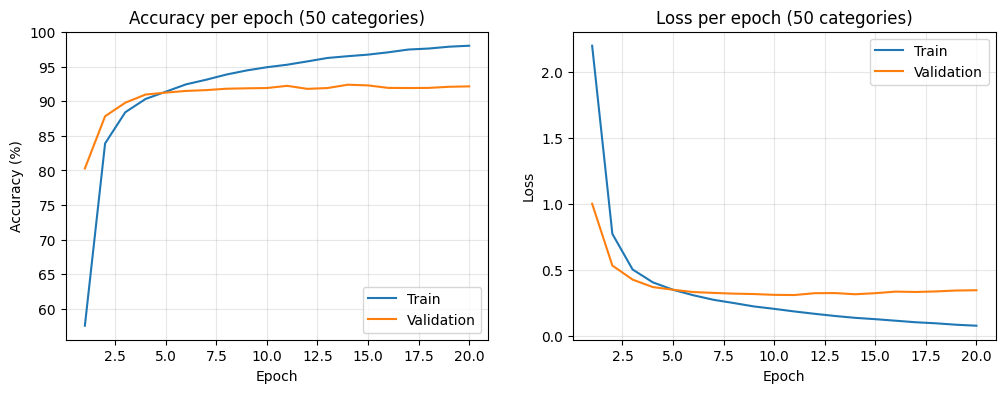

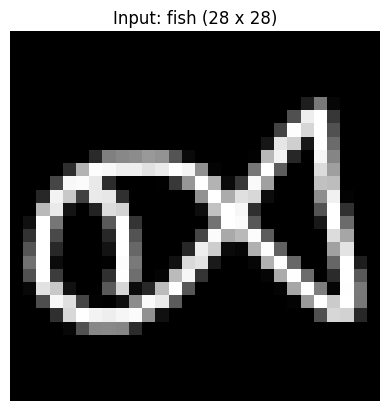

After conv1: (1, 64, 112, 112)


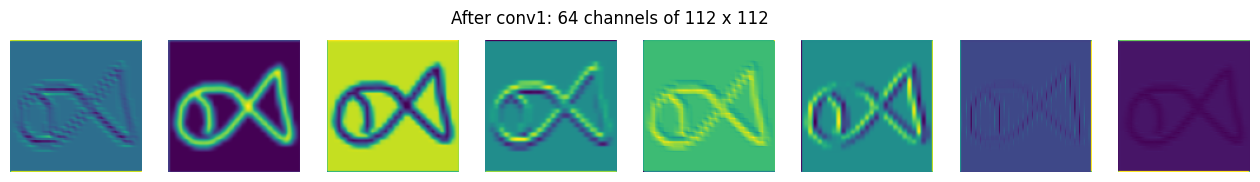

After bn1: (1, 64, 112, 112)


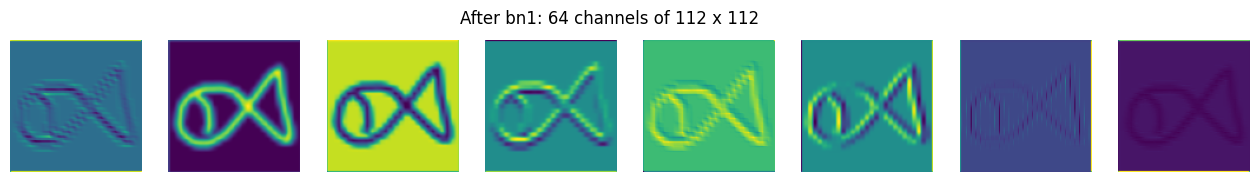

After relu: (1, 64, 112, 112)


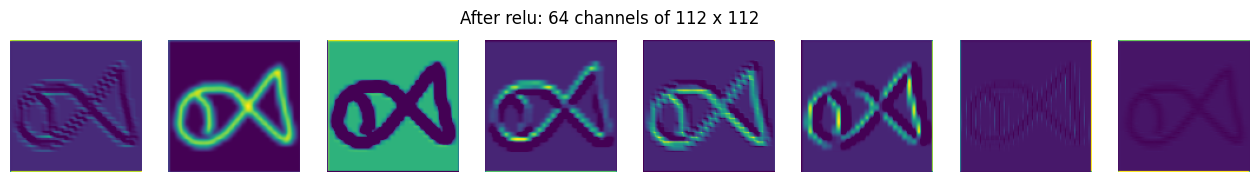

After maxpool: (1, 64, 56, 56)


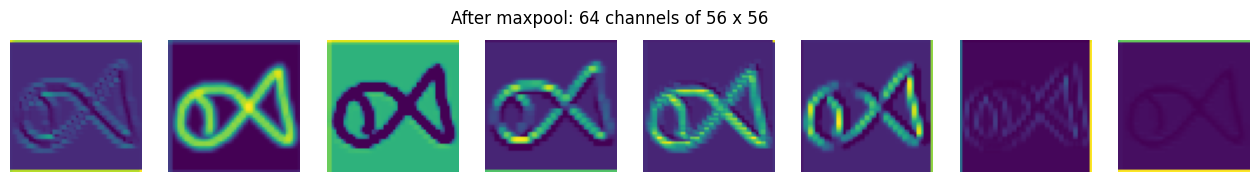

After layer1: (1, 256, 56, 56)


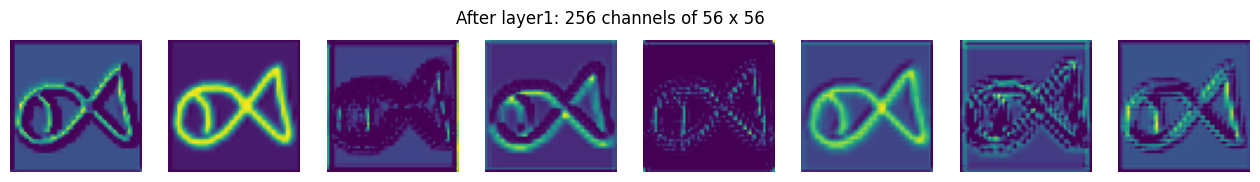

After layer2: (1, 512, 28, 28)


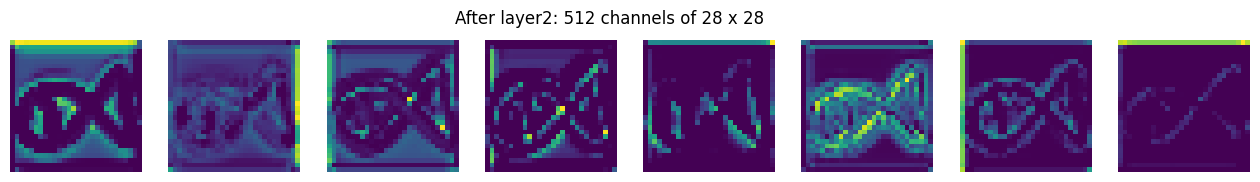

After layer3: (1, 1024, 14, 14)


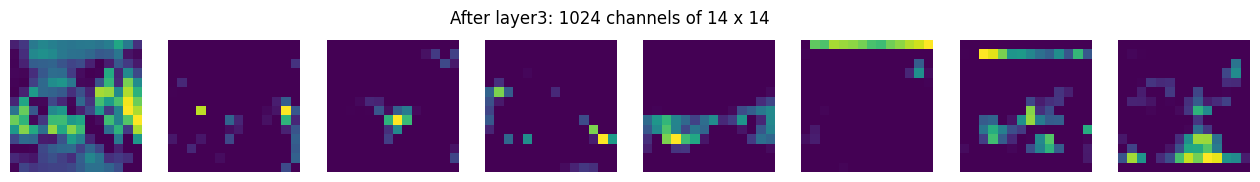

After layer4: (1, 2048, 7, 7)


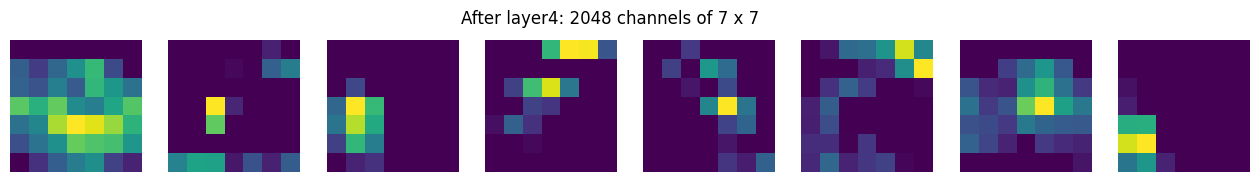

After avgpool: (1, 2048)
After fc: (1, 50)
Prediction: fish


In [ ]:
# =====================================================================
# SETTINGS (same as the paper)
# =====================================================================
N = 50              # number of categories (the first 50 in our list)
EPOCHS = 20         # paper: 20 epochs for 50 categories
BATCH_SIZE = 64     # paper: batch size 64
LR = 1e-5           # paper: learning rate 0.00001

# =====================================================================
# BUILD THE DATASET AND SPLIT IT
# =====================================================================
X = np.concatenate([data[c] for c in categories[:N]])        # all drawings of the first N categories
y = np.concatenate([np.full(1000, i) for i in range(N)])     # label for each drawing

# Split: 80% train, 10% validation, 10% test
X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=42)

# Convert to PyTorch tensors: pixels 0..255 -> 0..1, add channel: (28, 28) -> (1, 28, 28)
X_train = torch.tensor(X_train).float().div(255).unsqueeze(1)
X_val = torch.tensor(X_val).float().div(255).unsqueeze(1)
X_test = torch.tensor(X_test).float().div(255).unsqueeze(1)
y_train, y_val, y_test = torch.tensor(y_train), torch.tensor(y_val), torch.tensor(y_test)

# DataLoaders feed the model 64 images at a time
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=BATCH_SIZE)
print("Train:", len(X_train), "| Validation:", len(X_val), "| Test:", len(X_test))

# ImageNet mean and std (for normalizing)
mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

# Augmentation for training images only (same as the paper)
augment = torchvision.transforms.Compose([
    torchvision.transforms.RandomHorizontalFlip(),   # flip left-right half the time
    torchvision.transforms.RandomRotation(10),       # rotate between -10 and +10 degrees
])

# =====================================================================
# CREATE A FRESH RESNET-50 MODEL
# =====================================================================
model = torchvision.models.resnet50(weights="IMAGENET1K_V1")   # standard ResNet-50, ImageNet weights
model.fc = nn.Linear(2048, N)                                   # new last layer: 2048 features -> N categories
model = model.to(device)

loss_fn = nn.CrossEntropyLoss()                                 # paper: cross-entropy loss
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)        # paper: AdamW optimizer

# =====================================================================
# TRAIN AND VALIDATE
# =====================================================================
train_losses, train_accs, val_losses, val_accs = [], [], [], []

for epoch in range(EPOCHS):

    # ----- TRAINING -----
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        images = torch.stack([augment(img) for img in images])                    # random flip / rotate
        images = F.interpolate(images, size=(224, 224), mode="bilinear")          # resize 28x28 -> 224x224
        images = images.repeat(1, 3, 1, 1)                                        # 1 channel -> 3 channels
        images = (images - mean) / std                                            # normalize

        outputs = model(images)                  # forward pass
        loss = loss_fn(outputs, labels)          # how wrong the scores are

        optimizer.zero_grad()                    # clear old gradients
        loss.backward()                          # backward pass
        optimizer.step()                         # update the weights

        total_loss += loss.item() * len(labels)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += len(labels)

    train_losses.append(total_loss / total)
    train_accs.append(100 * correct / total)

    # ----- VALIDATION -----
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            images = F.interpolate(images, size=(224, 224), mode="bilinear")
            images = images.repeat(1, 3, 1, 1)
            images = (images - mean) / std

            outputs = model(images)
            total_loss += loss_fn(outputs, labels).item() * len(labels)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += len(labels)

    val_losses.append(total_loss / total)
    val_accs.append(100 * correct / total)

    print(f"Epoch {epoch+1}/{EPOCHS} | Train loss {train_losses[-1]:.4f}, acc {train_accs[-1]:.2f}% "
          f"| Val loss {val_losses[-1]:.4f}, acc {val_accs[-1]:.2f}%")

# =====================================================================
# TEST
# =====================================================================
model.eval()
total_loss, correct, total = 0, 0, 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        images = F.interpolate(images, size=(224, 224), mode="bilinear")
        images = images.repeat(1, 3, 1, 1)
        images = (images - mean) / std

        outputs = model(images)
        total_loss += loss_fn(outputs, labels).item() * len(labels)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += len(labels)

print(f"\nTEST ({N} categories): accuracy {100 * correct / total:.2f}%, loss {total_loss / total:.4f}")
print(f"PAPER (ResNet-50, {N} categories): accuracy 88.18%, loss 0.4284")

# =====================================================================
# ACCURACY AND LOSS GRAPHS
# =====================================================================
epochs = range(1, EPOCHS + 1)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_accs, label="Train")
plt.plot(epochs, val_accs, label="Validation")
plt.title(f"Accuracy per epoch ({N} categories)")
plt.xlabel("Epoch"); plt.ylabel("Accuracy (%)"); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs, train_losses, label="Train")
plt.plot(epochs, val_losses, label="Validation")
plt.title(f"Loss per epoch ({N} categories)")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

# =====================================================================
# LAYER BY LAYER OUTPUT FOR ONE FISH DRAWING
# =====================================================================
fish_index = (y_test == categories.index("fish")).nonzero()[0].item()   # first fish in the test set
image = X_test[fish_index:fish_index + 1].to(device)                     # shape: (1, 1, 28, 28)

plt.imshow(image[0, 0].cpu(), cmap="gray"); plt.title("Input: fish (28 x 28)"); plt.axis("off"); plt.show()

x = F.interpolate(image, size=(224, 224), mode="bilinear")
x = x.repeat(1, 3, 1, 1)
x = (x - mean) / std

layers = [("conv1", model.conv1), ("bn1", model.bn1), ("relu", model.relu), ("maxpool", model.maxpool),
          ("layer1", model.layer1), ("layer2", model.layer2), ("layer3", model.layer3), ("layer4", model.layer4)]

model.eval()
with torch.no_grad():
    for name, layer in layers:
        x = layer(x)                                         # pass through ONE layer
        print(f"After {name}: {tuple(x.shape)}")

        plt.figure(figsize=(16, 2))
        for i in range(8):                                   # show the first 8 channels
            plt.subplot(1, 8, i + 1)
            plt.imshow(x[0, i].cpu(), cmap="viridis")
            plt.axis("off")
        plt.suptitle(f"After {name}: {x.shape[1]} channels of {x.shape[2]} x {x.shape[3]}")
        plt.show()

    x = model.avgpool(x)                  # each 7x7 map -> 1 number  (2048 numbers)
    x = torch.flatten(x, 1)
    print("After avgpool:", tuple(x.shape))
    x = model.fc(x)                       # 2048 numbers -> N category scores
    print("After fc:", tuple(x.shape))
    print("Prediction:", categories[x.argmax(1).item()])